# Testing whether remembered contexts improve a combination

**Question:** Does the fixed ContextMemory rule improve mean final-block MASE over an otherwise matching recency-only combination on the fifteen selected cases?

## Objectives

Evaluate a particular forecasting proposal with an explicit way to reject its proposed benefit. ContextMemory estimates expert losses from completed historical origins, placing more weight on contexts similar to the current history. The hypothesis is that recurrence carries information beyond recency alone. We will execute the rule and two ablations, inspect their weights, check temporal availability and a change of units, then read the already fixed common-holdout experiment. We will retain its unfavorable aggregate result.

Feature-dependent forecast combination and dynamic ensembles already exist in the literature. FFORMA learns combinations across a reference collection; arbitrated dynamic ensembles estimate expert competence. The present rule tests a specific low-data, within-series memory construction. It does not establish priority for contextual weighting. The contribution under investigation is a concrete mechanism with reproducible settings, not the existence of an evaluation harness, a calibration wrapper or a favorable name for a familiar average.

## Setup

Use the isolated environment defined by the direct pins below. All three combinations import the same expert implementations. The notebook performs no search over their configuration after observing final-holdout results.

```text
pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0
```


In [1]:
# Configure a portable lesson session; no data are downloaded.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.model.forecasters import seasonal_naive, ses, holt, holt_winters, theta
from chronoscopelab.model.forecasters import gaussian_quantiles
from chronoscopelab.model.context_memory import fit_context_memory
from chronoscopelab.reevaluation import metrics
from chronoscopelab.engines.statsforecast_engine import StatsforecastForecaster
from chronoscopelab.engines.lightgbm_engine import LightGBMForecaster
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-lessons"
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "statsforecast", "lightgbm", "mlforecast",
            "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Data

The selected generated case provides a visible example of the fitting process. The complete artifact provides the predeclared aggregate comparison over fifteen final blocks. These serve different purposes: one case explains how weights arise, while the fixed collection evaluates the stated mean-error criterion. Both use committed histories and actual values. Model configuration is recorded in the artifact and the research dossier. Neither disappointing results nor a convenient individual success justify silently changing the kernel, expert roster or comparison collection.


In [2]:
# The committed trace separates available history from the unseen final block.
trace = json.loads((root / "data/derived/TRND_seasonal/trace.json").read_text())
history = np.array(trace["history"], dtype=float)
actual = np.array(trace["actual"], dtype=float)
m, h = trace["seasonality"], trace["horizon"]
comparison = json.loads((root / "data/derived/reevaluation.json").read_text())
print("History:", len(history), "Season:", m, "Holdout:", h)


History: 168 Season: 12 Holdout: 12


## Method

At up to twelve historical origins, the method fits five experts: SeasonalNaive, SES, Holt, HoltWinters and Theta. Every training target must end inside the currently available history. The query's final future block is excluded. Four context summaries describe normalized slope, level shift, volatility change and seasonal correlation. A Gaussian distance kernel compares remembered contexts with the query context. Recency decays with a fixed half-life of six remembered origins. These choices are implementation settings, not estimates selected from the final test errors.


In [3]:
# Fit the fixed context kernel using only completed targets within the history.
context_fit = fit_context_memory(history, m, h, mode="context")
print("Completed training origins:", len(context_fit.origins))
print("Latest training target ends:", max(context_fit.origins) + h)
print("Available history ends:", len(history))


Completed training origins: 12
Latest training target ends: 168
Available history ends: 168


The printed latest target endpoint can be compared directly with the available history length. Equality is allowed: the final remembered target may finish at the last observation already known. A target extending past that endpoint would be leakage. Forecast origins are not interchangeable with target endpoints, especially when the horizon spans many observations. The test suite exercises this boundary independently. In this notebook the printed endpoints make the same information constraint inspectable without confusing future observations loaded for scoring with inputs supplied to fitting.

RecencyMean removes the context-distance kernel but keeps the five experts, completed historical targets, recency decay and loss-to-weight transformation. This matching construction isolates whether context similarity adds value beyond a recent-loss estimate. Comparing ContextMemory only with a naive forecast would not answer that question: any gain could come from combining experts rather than from contextual memory. A useful ablation removes one proposed component while preserving the other relevant design choices.


In [4]:
# Remove context similarity while retaining the expert set and recency rule.
recency_fit = fit_context_memory(history, m, h, mode="recency")
print("Recency weights:", np.round(recency_fit.weights, 4))


Recency weights: [0.2659 0.1239 0.0144 0.4743 0.1216]


EqualMean gives every expert the same weight and therefore removes estimated competence preferences as well. It remains a genuine forecast using the same current expert paths. The interval columns are combined with the same convex weights as the point columns. Ordered input quantiles and nonnegative weights preserve quantile ordering, but this mathematical property does not establish probabilistic calibration. In particular, averaging marginal quantiles generally does not produce the quantiles of a mixture distribution. That distinction limits what the combined bands mean.


In [5]:
# The equal-weight ablation removes estimated loss preferences as well.
uniform_fit = fit_context_memory(history, m, h, mode="uniform")
print("Equal weights:", np.round(uniform_fit.weights, 4))


Equal weights: [0.2 0.2 0.2 0.2 0.2]


Local losses are shrunk one quarter toward the recency-only estimate before an exponential loss transform. A five-percent uniform floor then keeps every expert weight positive. These regularizers reduce concentration when very few remembered contexts are informative. They can also dilute a genuinely useful specialist. The first figure shows weights against expert names for the example case. It is an explanation of the fitted rule, rather than a causal attribution of which expert created the final error.


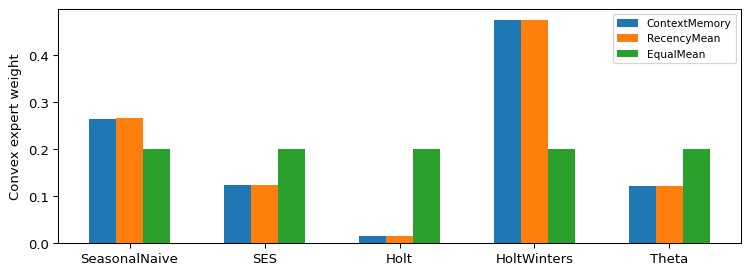

In [6]:
# Associate weights with expert identities rather than an unlabeled vector.
from chronoscopelab.model.context_memory import EXPERT_NAMES
fig, ax = plt.subplots()
x = np.arange(len(EXPERT_NAMES))
ax.bar(x - 0.2, context_fit.weights, width=0.2, label="ContextMemory")
ax.bar(x, recency_fit.weights, width=0.2, label="RecencyMean")
ax.bar(x + 0.2, uniform_fit.weights, width=0.2, label="EqualMean")
ax.set_xticks(x, EXPERT_NAMES)
ax.set(ylabel="Convex expert weight")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


The weight chart lets us inspect how much the context kernel actually changes the recency allocation. Similar bars imply that the proposed contextual component has little influence for this history. Different bars establish a changed decision, not a beneficial one. Only future targets can evaluate the consequences. EqualMean provides a fixed reference against which concentration is visible. No expert is removed after seeing its error in the final block, so this comparison preserves the declared roster.

## Comparison

Score the three newly computed paths on the same final target and historical seasonal scale. A lower case MASE is useful descriptive evidence, but one favorable example cannot resolve the aggregate hypothesis. The next cell prints all three results without selecting only the winner. This matters because context matching can help one regime and hurt another. A proposed method must retain both outcomes if the question concerns average performance across the fixed collection.


In [7]:
# Evaluate the ablations against the same target and the same history scale.
for name, fit in (("ContextMemory", context_fit), ("RecencyMean", recency_fit), ("EqualMean", uniform_fit)):
    q = fit.quantiles
    score = metrics(history, actual, q[:, 1], q[:, 0], q[:, 2], m)
    print(name, "case MASE", round(score["mase"], 4))


ContextMemory case MASE 0.5557
RecencyMean case MASE 0.5545
EqualMean case MASE 1.0389


Changing units provides a structural check independent of forecast ranking. The context summaries and normalized losses are designed to be invariant to a positive change of scale and a common shift. Multiplying the history by ten and adding one hundred should therefore leave the convex weights unchanged apart from numerical rounding. This check does not measure future accuracy; it asks whether a transformation that preserves the series' relative structure changes the proposed rule unnecessarily.


In [8]:
# Changing units should preserve the context rule's convex weights.
converted = fit_context_memory(history * 10 + 100, m, h, mode="context")
print("Maximum weight change after unit conversion:", f"{np.max(np.abs(converted.weights - context_fit.weights)):.8f}")


Maximum weight change after unit conversion: 0.00000000


## Evidence

The predeclared primary criterion is mean MASE across all fifteen common final blocks. ContextMemory must improve on RecencyMean to support a benefit from context matching in this experiment. The final figure reads every case's already persisted aggregate, including unfavorable cases, without refitting or tuning. The benchmark contains only one origin per selected series, so it supports neither significance nor a population-wide conclusion. Nevertheless, it can reject a claimed aggregate improvement on this exact collection.


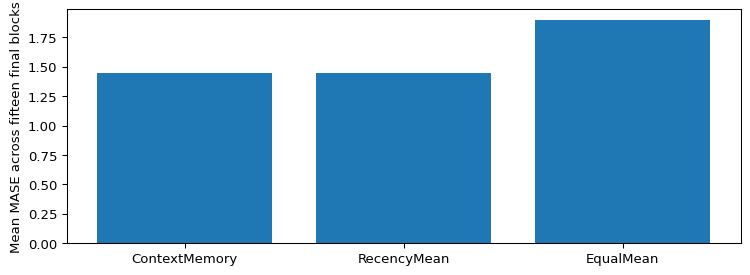

ContextMemory mean MASE 1.4504
RecencyMean mean MASE 1.4489
EqualMean mean MASE 1.8970


In [9]:
# Read the already fixed fifteen-case experiment, without tuning to its outcomes.
names = ["ContextMemory", "RecencyMean", "EqualMean"]
means = [next(row["mean_mase"] for row in comparison["summary"] if row["name"] == name) for name in names]
fig, ax = plt.subplots()
ax.bar(names, means)
ax.set(ylabel="Mean MASE across fifteen final blocks")
fig.tight_layout()
plt.show()
for name, value in zip(names, means, strict=True):
    print(name, "mean MASE", f"{value:.4f}")


The aggregate bars show the small difference between the contextual and recency-only variants and the larger gap to EqualMean. Because the contextual mean is slightly higher, this experiment does not support the proposed component at the declared criterion. Rounding the bars to two decimal places would hide that result; the printed four-decimal values preserve it. A failed comparison remains evidence and should constrain the manuscript's claim rather than trigger unreported tuning.

### Sensitivity across the selected cases

At a query origin, let $u$ be the standardized context, $u_i$ a completed memory's context, $a_i$ its age in remembered origins, and $b$ the bandwidth derived from distances to available contexts. The relative weight for its loss is

$$
k_i=2^{-a_i/6}\exp\!\left(-\frac{\|u-u_i\|^2}{2b^2}\right).
$$

Let $L_j$ denote the resulting loss for expert $j$, after shrinking toward the recency-only estimate. With temperature $T=1$ and uniform floor $\eta=.05$, the final weight is

$$
w_j=(1-\eta)\frac{\exp[-(L_j-\min_k L_k)/T]}{\sum_r\exp[-(L_r-\min_k L_k)/T]}+\frac{\eta}{5}.
$$

Subtracting the minimum loss keeps the leading exponential at one and improves numerical stability. The recency ablation uses the same loss transformation and floor with the context kernel set to one. The fit needs enough completed memory to estimate a meaningful local loss. A close context may carry little weight if it is old, while a distant but recent context can remain influential when all observed distances are large. The weights can move even when the combined point forecast changes very little because different experts sometimes predict almost the same path.

The next figure pairs the two scores inside each case. A negative bar means that ContextMemory had lower MASE on that case. The mean reflects magnitude, so a few relatively large losses can offset more numerous small improvements. The median and direction counts provide complementary descriptions of the same fifteen cases. Their ordering in the chart follows the published inventory and has no temporal meaning.


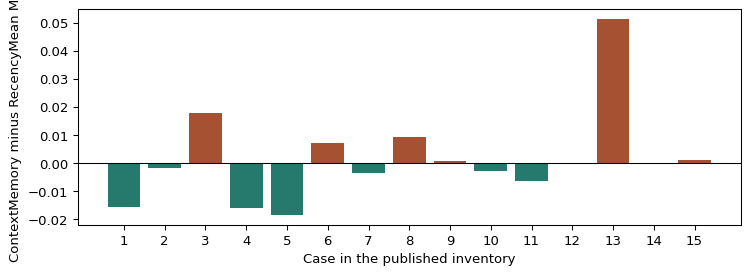

Lower, tied, higher: 7 0 8
Mean and median difference: [1.552e-03 1.300e-05]


In [10]:
# Pair the two rules within each case before aggregating the differences.
differences = []
for case in comparison["cases"]:
    by_name = {row["name"]: row["metrics"]["mase"] for row in case["methods"]}
    differences.append(by_name["ContextMemory"] - by_name["RecencyMean"])
delta = np.asarray(differences)
fig, ax = plt.subplots()
positions = np.arange(1, len(delta) + 1)
ax.bar(positions, delta, color=np.where(delta < 0, "#267a6d", "#a65132"))
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="Case in the published inventory", ylabel="ContextMemory minus RecencyMean MASE")
ax.set_xticks(positions)
fig.tight_layout()
plt.show()
print("Lower, tied, higher:", int(sum(delta < 0)), int(sum(delta == 0)), int(sum(delta > 0)))
print("Mean and median difference:", np.round([delta.mean(), np.median(delta)], 6))


These comparisons reuse the reserved outcomes. They diagnose variation in the fixed experiment and do not choose new settings. In particular, removing an adverse case because its bar is large would silently change the criterion. Future testing can predeclare distinct mechanism groups and suitable sample sizes, with each series supplying the resampling unit if it contributes multiple origins. The sensitivity of the historical mean to the case mix is a reason to retain the paired paths and their data provenance.

### Apply the comparison to your own data

Start with contiguous observations and a declared seasonal period. Choose a horizon and use the same five experts in all ablations. For each evaluation origin, admit only training memories whose full targets have already arrived. Save each memory's origin, endpoint, context and expert scores before computing weights. If histories come from multiple stores or instruments, keep each series identity and scale in the record. A common MASE scale within each case allows a dimensionless paired difference; comparing raw interval widths across incompatible units does not.

Reserve a final set of origins before exploring alternative temperatures, bandwidths or floors. If a setting is tuned, select it on completed historical blocks within the fitting prefix and compare it once on the reserved targets. Record whether the recency-only control is included in that selection. The actual question is how much the extra context calculation contributes when the expert paths and evaluation design are held fixed. Keep the uniform reference to show the benefit of estimated preferences separately.

## Results

**Answer:** ContextMemory has mean MASE 1.4504 and RecencyMean 1.4489. The contextual rule therefore fails its declared mean-error criterion on this selected collection. EqualMean has mean MASE 1.8970. Combining experts with estimated recent losses helped relative to that equal average here, but the additional context kernel did not improve the primary comparison.

These numbers do not establish equivalence or prove that contextual weighting can never help. They identify an unsuccessful fixed experiment. A follow-up should declare broader data, repeated origins, dependence-aware uncertainty and runtime accounting before execution. Any changed settings define a new experiment and must not overwrite this one. The historical origins used to estimate weights are training information, not extra independent final-test replications.

## Summary

A testable proposal needs a mechanism, matching ablations, a temporal information boundary and an explicit failure criterion. ContextMemory supplies those pieces and receives a negative initial result. Preserve the implementation, settings, individual predictions and aggregate values so another researcher can inspect the failure. Further research may improve the rule or reject its premise; neither outcome justifies claiming superiority from the current experiment.

## References

- Feature-dependent averaging: https://doi.org/10.1016/j.ijforecast.2019.02.011
- Dynamic ensembles: https://doi.org/10.1007/s10994-018-05774-y
- Forecast scaling: https://doi.org/10.1016/j.ijforecast.2006.03.001
- Expert Theta equation: https://robjhyndman.com/papers/Theta.pdf
- Seasonal expert continuation: https://otexts.com/fpp3/holt-winters.html
